# Applications of Clustering and PCA

No new algorithms. The same K-Means, DBSCAN and PCA from weeks 7 and 8, asked new questions: which samples are odd, how to compress an image, which samples to label, and which features to build.

### Table of contents
1. [Anomaly detection](#1.-Anomaly-detection)
2. [Image segmentation: color quantization](#2.-Image-segmentation:-color-quantization)
3. [Semi-supervised learning](#3.-Semi-supervised-learning)
4. [Unsupervised as preprocessing](#4.-Unsupervised-as-preprocessing)
5. [Exercises](#5.-Exercises)

## 1. Anomaly detection

The recipe for every method: learn what normal looks like, give each sample an **anomaly score**, flag the samples whose score passes a **threshold**.

### One dataset, four tools

Two stretched groups along one line, plus 6 points we planted as anomalies. We know which ones they are; the methods do not.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
along = np.array([1.0, 0.55]) / np.linalg.norm([1.0, 0.55])   # direction of the line
across = np.array([-along[1], along[0]])                        # at a right angle to it

def stretched_group(center, n):
    return center + np.outer(rng.normal(0, 0.95, n), along) + np.outer(rng.normal(0, 0.28, n), across)

normal_points = np.vstack([stretched_group(-4.0 * along, 170), stretched_group(4.0 * along, 170)])
planted = np.array([
    [-1.5, 2.6], [2.2, -2.4], [-4.8, 1.2], [5.0, -0.4],   # off the line
    [0.0, 0.0],                                           # on the line, between the groups
    [8.6, 4.8],                                           # far out along the line
])
X_anom = np.vstack([normal_points, planted])
is_planted = np.r_[np.zeros(len(normal_points), bool), np.ones(len(planted), bool)]
print("samples:", X_anom.shape, " planted anomalies:", is_planted.sum())

samples: (346, 2)  planted anomalies: 6


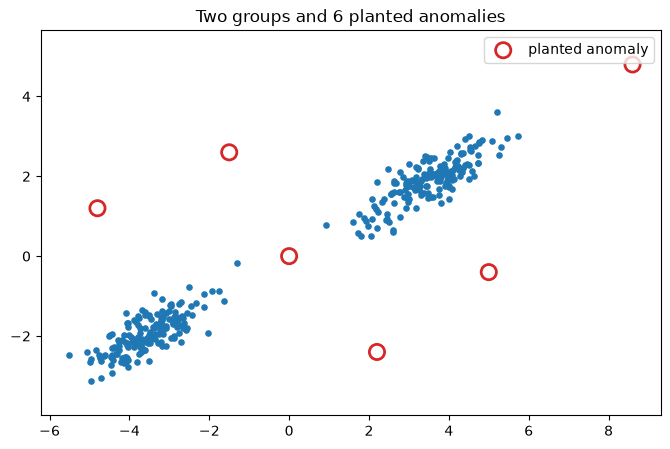

In [2]:
plt.figure(figsize=(8, 5))
plt.scatter(*X_anom[~is_planted].T, s=14)
plt.scatter(*X_anom[is_planted].T, s=120, facecolors="none", edgecolors="tab:red", linewidths=2, label="planted anomaly")
plt.axis("equal")
plt.title("Two groups and 6 planted anomalies")
plt.legend()
plt.show()

We flag the top 2% of scores with each tool, which is 7 samples here:

In [3]:
def flag_top(scores, rate=0.02):
    return scores > np.percentile(scores, 100 * (1 - rate))

**K-Means:** normal means close to a centroid. `transform` gives the distance to every centroid; the score is the smallest one.

In [4]:
from sklearn.cluster import KMeans

kmeans_anom = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_anom)
kmeans_scores = kmeans_anom.transform(X_anom).min(axis=1)
kmeans_flags = flag_top(kmeans_scores)

**DBSCAN:** normal means inside a dense region. Noise points (`-1`) are the anomalies, with no score and no threshold.

In [5]:
from sklearn.cluster import DBSCAN

dbscan_flags = DBSCAN(eps=0.7, min_samples=6).fit(X_anom).labels_ == -1

**Gaussian Mixture:** fits a stretched bell shape to each group; normal means high density. `score_samples` returns the log density, so we flip its sign.

In [6]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=2, random_state=42).fit(X_anom)
gmm_scores = -gmm.score_samples(X_anom)
gmm_flags = flag_top(gmm_scores)

**PCA:** normal means close to the main direction. The score is each sample's reconstruction error, from the last notebook.

In [7]:
from sklearn.decomposition import PCA

pca_anom = PCA(n_components=1).fit(X_anom)
X_anom_back = pca_anom.inverse_transform(pca_anom.transform(X_anom))
pca_scores = ((X_anom - X_anom_back) ** 2).sum(axis=1)
pca_flags = flag_top(pca_scores)

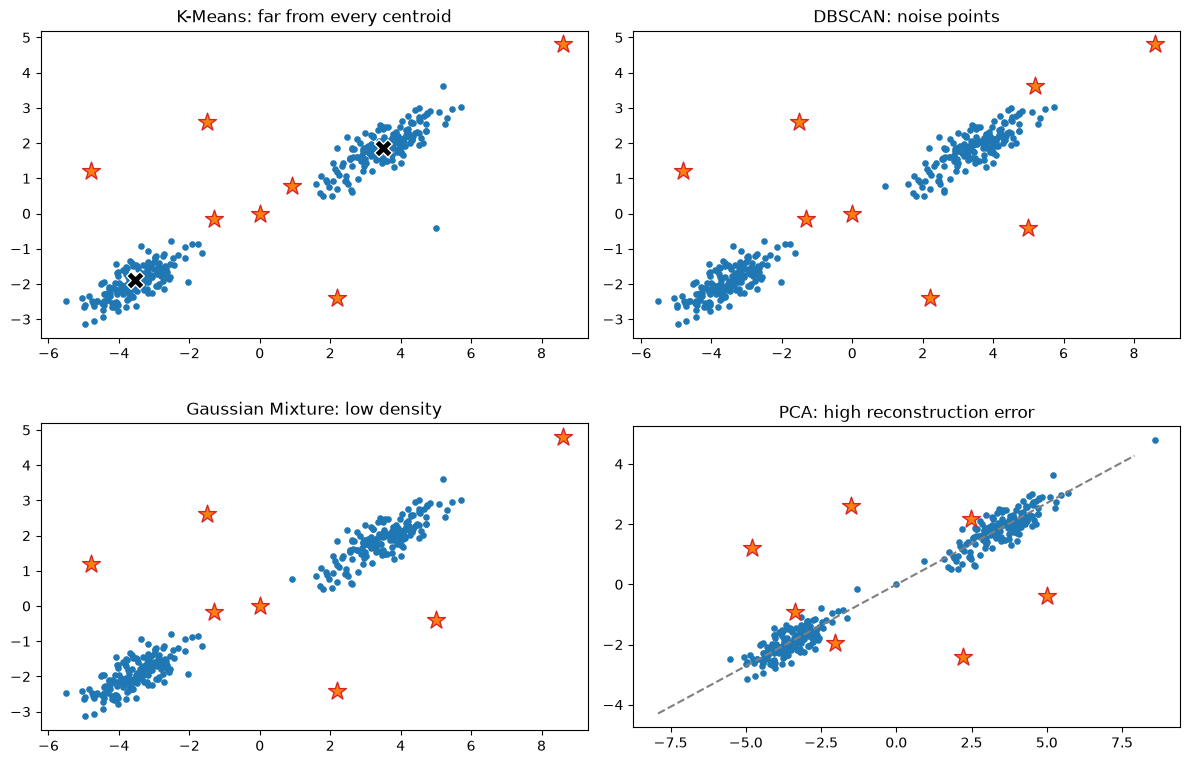

In [8]:
results = {
    "K-Means: far from every centroid": kmeans_flags,
    "DBSCAN: noise points": dbscan_flags,
    "Gaussian Mixture: low density": gmm_flags,
    "PCA: high reconstruction error": pca_flags,
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (title, flags) in zip(axes.ravel(), results.items()):
    ax.scatter(*X_anom[~flags].T, s=14)
    ax.scatter(*X_anom[flags].T, s=180, marker="*", color="tab:orange", edgecolor="tab:red", zorder=3)
    ax.set_title(title)
    ax.set_aspect("equal")
axes[0, 0].scatter(*kmeans_anom.cluster_centers_.T, s=160, marker="X", c="black", edgecolor="white")
line = pca_anom.mean_ + np.outer([-9, 9], pca_anom.components_[0])
axes[1, 1].plot(*line.T, "--", color="gray")
plt.tight_layout()
plt.show()

Which planted points did each tool catch?

In [ ]:
planted = np.array([
    [-1.5, 2.6], [2.2, -2.4], [-4.8, 1.2], [5.0, -0.4],   # off the line
    [0.0, 0.0],                                           # on the line, between the groups
    [8.6, 4.8],                                           # far out along the line
])

In [9]:
kinds = ["off the line"] * 4 + ["between the groups", "far along the line"]
pd.DataFrame({title.split(":")[0]: flags[is_planted] for title, flags in results.items()},
             index=[f"{i}: {kind}" for i, kind in enumerate(kinds)])

,K-Means,DBSCAN,Gaussian Mixture,PCA
0: off the line,True,True,True,True
1: off the line,True,True,True,True
2: off the line,True,True,True,True
3: off the line,False,True,True,True
4: between the groups,True,True,True,False
5: far along the line,True,True,True,False


PCA misses the point between the groups and the one far along the line: they sit on the main direction, so they rebuild perfectly. Choose the tool by what "unusual" means in your problem.

`scikit-learn` also has tools made only for this job, such as `IsolationForest` and `LocalOutlierFactor`. The idea behind them is the same.

### Choosing the threshold, on Wine

Score every wine by its reconstruction error with 8 components (90% of the variance), as in the last notebook.

In [10]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine(as_frame=True)
X_wine = wine.data
X_wine_scaled = StandardScaler().fit_transform(X_wine)

pca_wine = PCA(n_components=8).fit(X_wine_scaled)
X_wine_back = pca_wine.inverse_transform(pca_wine.transform(X_wine_scaled))
wine_scores = ((X_wine_scaled - X_wine_back) ** 2).mean(axis=1)

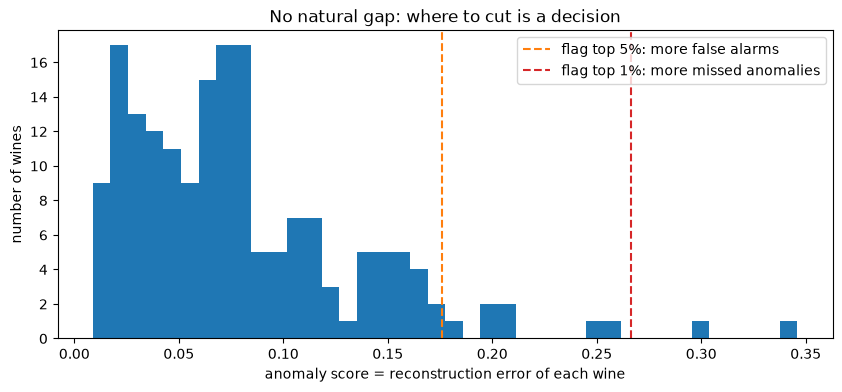

In [11]:
loose, strict = np.percentile(wine_scores, 95), np.percentile(wine_scores, 99)

plt.figure(figsize=(10, 4))
plt.hist(wine_scores, bins=40)
plt.axvline(loose, color="tab:orange", linestyle="--", label="flag top 5%: more false alarms")
plt.axvline(strict, color="tab:red", linestyle="--", label="flag top 1%: more missed anomalies")
plt.xlabel("anomaly score = reconstruction error of each wine")
plt.ylabel("number of wines")
plt.title("No natural gap: where to cut is a decision")
plt.legend()
plt.show()

If we know roughly how common anomalies are, say 2%, cut at that percentile:

In [12]:
threshold = np.percentile(wine_scores, 98)
flagged = np.where(wine_scores > threshold)[0]

print("threshold:", threshold.round(3))
print("flagged wines:", flagged)

threshold: 0.227
flagged wines: [ 73  84 105 121]


Why is the top one unusual? Its scaled features show how many standard deviations it sits from the average wine.

In [13]:
top_wine = flagged[np.argmax(wine_scores[flagged])]
pd.Series(X_wine_scaled[top_wine], index=X_wine.columns).round(2).sort_values(key=abs, ascending=False).head(4)

alcalinity_of_ash    3.15
magnesium            2.76
total_phenols        1.61
hue                  1.55
dtype: float64

In [14]:
X_wine.loc[top_wine, ["alcalinity_of_ash", "magnesium"]].to_frame("this wine").join(
    X_wine[["alcalinity_of_ash", "magnesium"]].agg(["mean", "max"]).T)

,this wine,mean,max
alcalinity_of_ash,30.0,19.494944,30.0
magnesium,139.0,99.741573,162.0


It has the highest `alcalinity_of_ash` of all 178 wines, plus high `magnesium`: a combination the main directions do not explain. Whether that is a measurement error or a real oddity is a question for a person, not for the model.

## 2. Image segmentation: color quantization

A photo that ships with `scikit-learn`. Each pixel is a sample with 3 features: red, green and blue.

In [15]:
from sklearn.datasets import load_sample_image

image = load_sample_image("flower.jpg")
pixels = image.reshape(-1, 3)

print("image:", image.shape, " pixels as a table:", pixels.shape)
print("different colors:", len(np.unique(pixels, axis=0)))

image: (427, 640, 3)  pixels as a table: (273280, 3)
different colors: 62941


K-Means groups similar colors. Every pixel then takes the color of its cluster's centroid.

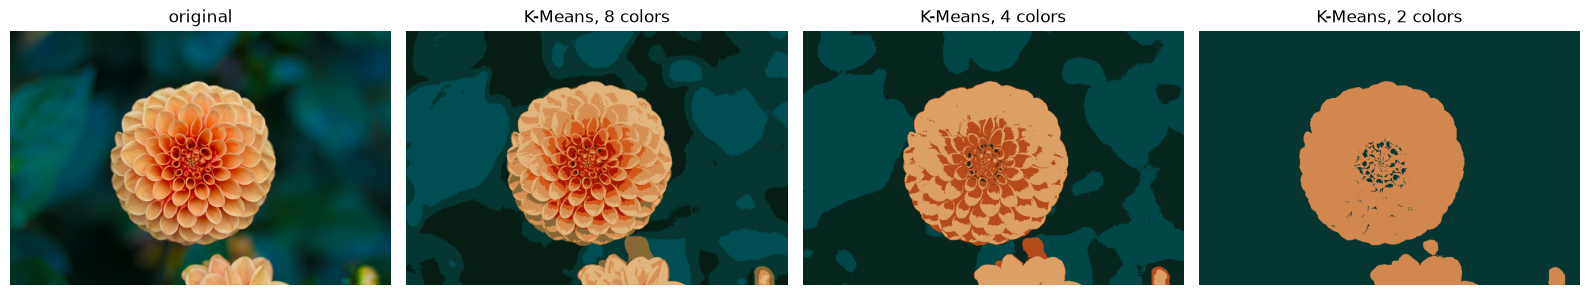

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
axes[0].imshow(image)
axes[0].set_title("original")
for ax, k in zip(axes[1:], [8, 4, 2]):
    kmeans_colors = KMeans(n_clusters=k, random_state=42, n_init=4).fit(pixels)
    new_pixels = kmeans_colors.cluster_centers_[kmeans_colors.labels_]
    ax.imshow(new_pixels.reshape(image.shape).astype("uint8"))
    ax.set_title(f"K-Means, {k} colors")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

With 2 colors the flower separates from the background. K-Means sees only color, not shape, so real object segmentation needs neural networks.

## 3. Semi-supervised learning

Digits again: 1,400 training images, but labeling costs money and we can afford only 50 labels. Which 50 should we pay for?

In [17]:
from sklearn.datasets import load_digits

X_digits, y_digits = load_digits(return_X_y=True)
X_train, y_train = X_digits[:1400], y_digits[:1400]
X_test, y_test = X_digits[1400:], y_digits[1400:]

Baseline: label the first 50 images and train a classifier on them.

In [18]:
from sklearn.linear_model import LogisticRegression

def test_accuracy(X_labeled, y_labeled):
    model = LogisticRegression(max_iter=10_000).fit(X_labeled, y_labeled)
    return model.score(X_test, y_test)

accuracy_first_50 = test_accuracy(X_train[:50], y_train[:50])
print(f"50 first images labeled: {accuracy_first_50:.1%}")

50 first images labeled: 75.8%


Now let K-Means choose. Split the 1,400 images into 50 clusters and label only the image closest to each centroid.

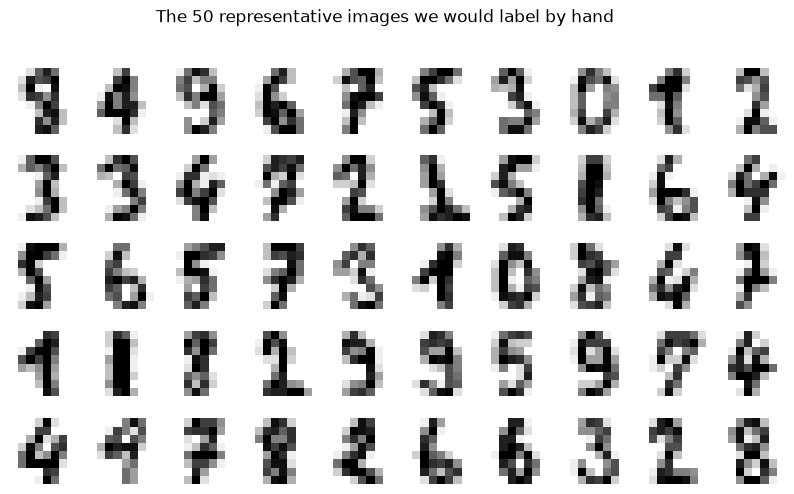

In [19]:
kmeans_50 = KMeans(n_clusters=50, random_state=42, n_init=10)
distances = kmeans_50.fit_transform(X_train)        # 1400 x 50: distance from each image to each centroid
representative_idx = distances.argmin(axis=0)      # closest image to each centroid

fig, axes = plt.subplots(5, 10, figsize=(10, 5.5))
for ax, idx in zip(axes.ravel(), representative_idx):
    ax.imshow(X_train[idx].reshape(8, 8), cmap="binary")
    ax.axis("off")
plt.suptitle("The 50 representative images we would label by hand")
plt.show()

A person would label these 50. Here `y_train` plays that person.

In [20]:
y_representative = y_train[representative_idx]

accuracy_representative = test_accuracy(X_train[representative_idx], y_representative)
print(f"50 representative images labeled: {accuracy_representative:.1%}")

50 representative images labeled: 83.9%


One step further, **label propagation**: give each representative's label to every image in its cluster.

In [21]:
y_propagated = y_representative[kmeans_50.labels_]
print(f"propagated labels that are correct: {(y_propagated == y_train).mean():.1%}")

accuracy_propagated = test_accuracy(X_train, y_propagated)
accuracy_all = test_accuracy(X_train, y_train)

propagated labels that are correct: 95.0%


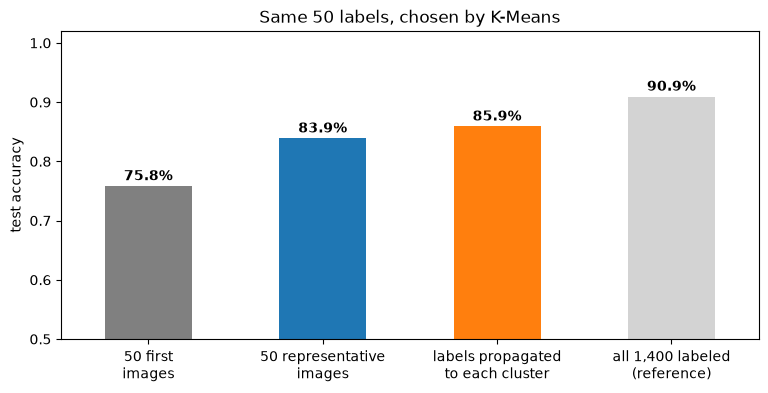

In [22]:
accuracies = pd.Series({
    "50 first\nimages": accuracy_first_50,
    "50 representative\nimages": accuracy_representative,
    "labels propagated\nto each cluster": accuracy_propagated,
    "all 1,400 labeled\n(reference)": accuracy_all,
})

ax = accuracies.plot.bar(figsize=(9, 4), rot=0, color=["gray", "tab:blue", "tab:orange", "lightgray"])
for i, value in enumerate(accuracies):
    ax.text(i, value + 0.01, f"{value:.1%}", ha="center", fontweight="bold")
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("test accuracy")
ax.set_title("Same 50 labels, chosen by K-Means")
plt.show()

Same labeling budget, much better model. The only change is which samples got labeled.

## 4. Unsupervised as preprocessing

PCA and K-Means both have `transform`, so they can be a step in a `Pipeline`, just like `StandardScaler` in week 6.

### PCA before a classifier

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

Xd_train, Xd_test, yd_train, yd_test = train_test_split(X_digits, y_digits, test_size=0.2, random_state=42, stratify=y_digits)

without_pca = Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))])
with_pca = Pipeline([("scale", StandardScaler()), ("pca", PCA(n_components=0.95)), ("clf", LogisticRegression(max_iter=5000))])

for name, model in [("without PCA", without_pca), ("with PCA", with_pca)]:
    model.fit(Xd_train, yd_train)
    n_features = model.named_steps["pca"].n_components_ if "pca" in model.named_steps else 64
    print(f"{name:12}  features: {n_features:2}   test accuracy: {model.score(Xd_test, yd_test):.1%}")

without PCA   features: 64   test accuracy: 97.2%
with PCA      features: 40   test accuracy: 95.3%


64 features down to 40, and a small drop in accuracy. Fewer dimensions is not automatically a better model.

### K-Means distances as new features

California Housing, from weeks 3 and 6. Can "distance to busy areas" help predict house prices?

In [24]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
Xh_train, Xh_test, yh_train, yh_test = train_test_split(housing.data, housing.target, test_size=0.2, random_state=42)

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

def cv_rmse(model):
    return -cross_val_score(model, Xh_train, yh_train, cv=5, scoring="neg_root_mean_squared_error").mean()

baseline = Pipeline([("scale", StandardScaler()), ("reg", LinearRegression())])
print(f"baseline RMSE: {cv_rmse(baseline):.3f}")

baseline RMSE: 0.721


First try: replace the features with their distances to 10 centroids.

In [26]:
distances_only = Pipeline([
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=10, random_state=42)),   # 8 features in, 10 distances out
    ("reg", LinearRegression()),
])
print(f"distances only RMSE: {cv_rmse(distances_only):.3f}")

distances only RMSE: 0.827


Worse. The model lost the 8 original features and kept only 10 distances. Better: cluster only the location, and keep every other feature, with a `ColumnTransformer`.

In [27]:
from sklearn.compose import ColumnTransformer

geo_features = Pipeline([
    ("features", ColumnTransformer(
        [("geo", KMeans(n_clusters=20, random_state=42), ["Latitude", "Longitude"])],
        remainder="passthrough",                          # keep the other 6 features as they are
    )),
    ("scale", StandardScaler()),
    ("reg", LinearRegression()),
])
print(f"original features + 20 location distances RMSE: {cv_rmse(geo_features):.3f}")

original features + 20 location distances RMSE: 0.678


Better than the baseline. `n_clusters` is a hyperparameter like any other, so `GridSearchCV` from week 6 can tune it.

In [28]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(geo_features, {"features__geo__n_clusters": [10, 20, 50, 100]},
                      cv=3, scoring="neg_root_mean_squared_error")
search.fit(Xh_train, yh_train)

print("best n_clusters:", search.best_params_["features__geo__n_clusters"])
print(f"best RMSE: {-search.best_score_:.3f}")

best n_clusters: 100
best RMSE: 0.591


100 is the largest value in the grid, so an even larger one might do better. Where are those centroids? On a map of the houses:

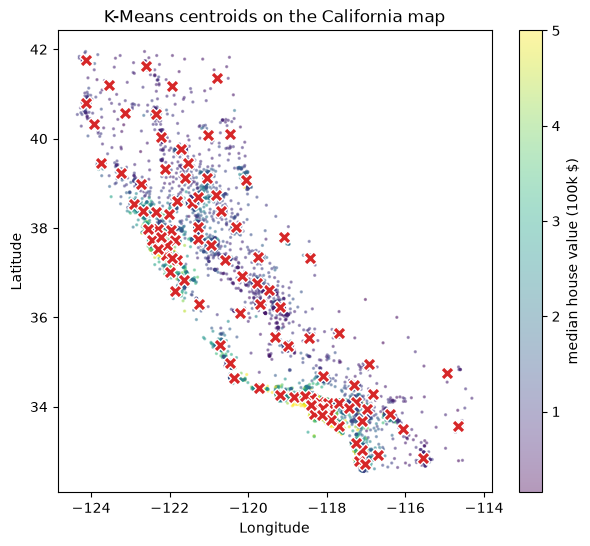

In [29]:
geo_kmeans = search.best_estimator_.named_steps["features"].named_transformers_["geo"]

plt.figure(figsize=(7, 6))
plt.scatter(Xh_train["Longitude"], Xh_train["Latitude"], c=yh_train, s=2, cmap="viridis", alpha=0.4)
plt.colorbar(label="median house value (100k $)")
plt.scatter(geo_kmeans.cluster_centers_[:, 1], geo_kmeans.cluster_centers_[:, 0], marker="X", s=90, c="tab:red", edgecolor="white")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("K-Means centroids on the California map")
plt.show()

Centroids crowd where houses crowd, around Los Angeles and the Bay Area. A linear model cannot draw such regions from raw latitude and longitude; distances to the centroids give it that information.

## 5. Exercises

1. **Anomaly detection:** change `rate` in `flag_top` to `0.05`. Which tools start flagging normal points?

2. **Anomaly detection:** try `IsolationForest(random_state=42)` from `sklearn.ensemble` on `X_anom`, with `-iso.score_samples(X_anom)` as the score. Which planted points does it catch?
3. **Wine:** which wines get flagged with 2 components instead of 8? Are they the same ones?
4. **Color quantization:** load your own photo with `plt.imread("your_photo.jpg")` and find the smallest `k` that still looks right to you.
5. **Semi-supervised:** repeat Section 3 with 20 and 100 labels. Does the gap between the first images and the representative images grow or shrink?
6. **Preprocessing:** in the digits `Pipeline`, try `PCA(n_components=0.80)` and `PCA(n_components=0.99)`. How do the number of features and the accuracy change?
7. **K-Means features:** extend the grid beyond 100 clusters. Where does the RMSE stop improving?